[Original Study Here](https://pmc.ncbi.nlm.nih.gov/articles/PMC9518652/)

Start by importing the datasets and methods used. This is a replication study of our parent paper. We recreated the data cleanup, EDA, preprocessing, and two feature models. All of the code is referenced from the paper and outlined by ChatGPT. 

The primary goal of this model is to predict the amount of cases in 2021 given the amount of cases in 2020. This involves columns life expectancy, expected schooling, mean schooling, GNI per capita, COVID cases per million in 2020, and COVID cases per million in 2021. 

This dataset is a combination of two datasets, OWID and HDI in 2020. This has been recreated later with archives of datasets, which accounts for the discrepancies between the data. The datasets were combined and preprocessed in R. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict, cross_validate

from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    max_error,
    make_scorer
)

In [3]:
df = pd.read_csv("train_set_new.csv")

columns = [
    "CASES_2020", "CASES_2021", "CASES_2022", "CASES_2023", "LIFE_EXP_2020", "LIFE_EXP_2021", "LIFE_EXP_2022", "LIFE_EXP_2023", "EXP_SCHOOLING_2020", "EXP_SCHOOLING_2021", "EXP_SCHOOLING_2022", "EXP_SCHOOLING_2023", "MEAN_SCHOOLING_2020", "MEAN_SCHOOLING_2021", "MEAN_SCHOOLING_2022", "MEAN_SCHOOLING_2023", "GNI_2020", "GNI_2021", "GNI_2022", "GNI_2023"
]

print(df[columns].describe())

          CASES_2020     CASES_2021     CASES_2022     CASES_2023  \
count     128.000000     128.000000     128.000000     128.000000   
mean    16424.794775   66628.690787  170578.299948  177895.194687   
std     19949.869712   65507.004454  186903.612448  198811.666665   
min         0.257592       9.290658     375.079350     375.909000   
25%       804.222575    4683.305950   15390.214250   15689.172750   
50%      7983.601850   53565.620000   96901.530000   99217.430000   
75%     29530.878500  106039.265000  264701.357500  277633.705000   
max    100135.470000  286282.340000  678216.500000  741418.250000   

       LIFE_EXP_2020  LIFE_EXP_2021  LIFE_EXP_2022  LIFE_EXP_2023  \
count     128.000000     128.000000     128.000000     128.000000   
mean       72.168028      71.447295      72.968016      73.516706   
std         6.925981       7.087320       6.696124       6.830854   
min        53.082000      53.136000      54.528000      55.069000   
25%        66.922750      66.1820

These numbers are close to Table 3. in the original paper. 
Distibution Plots

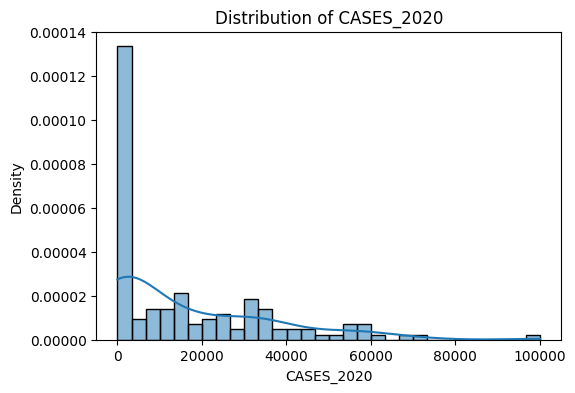

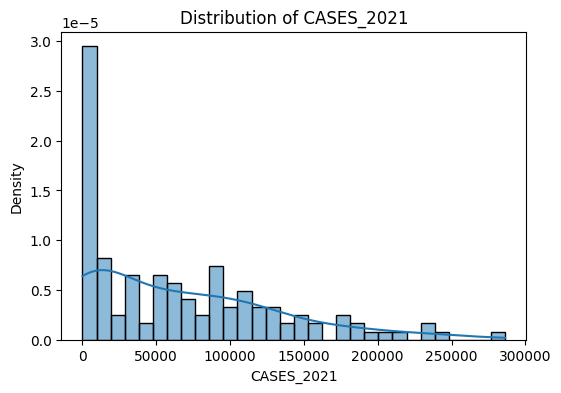

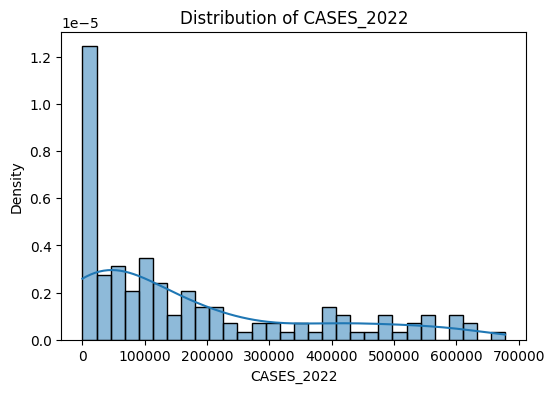

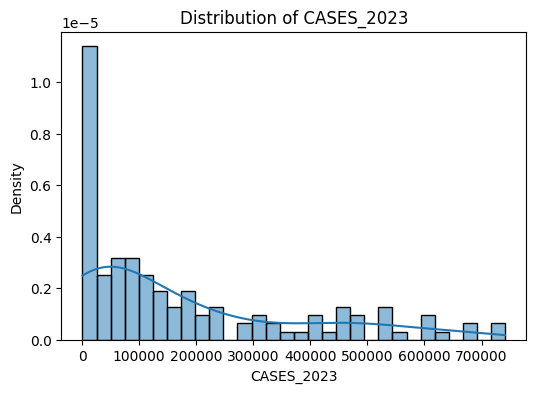

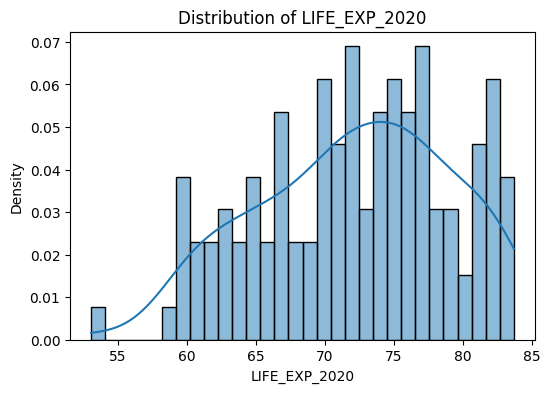

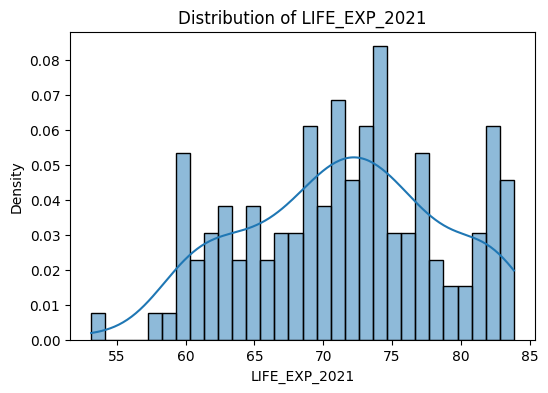

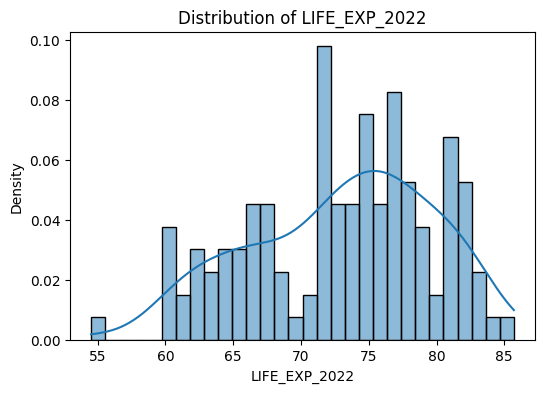

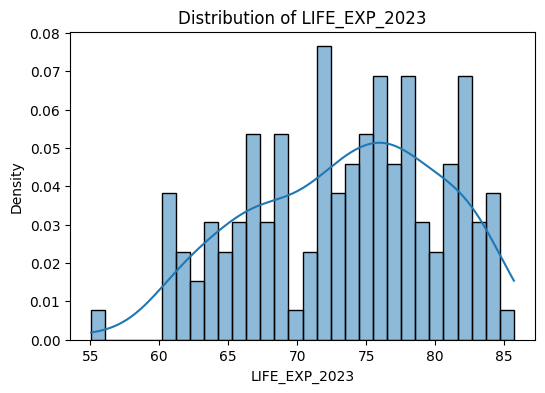

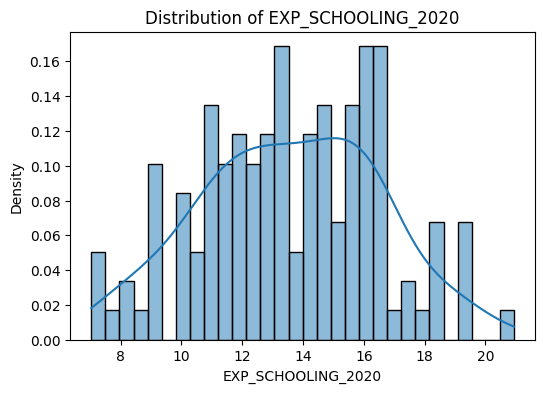

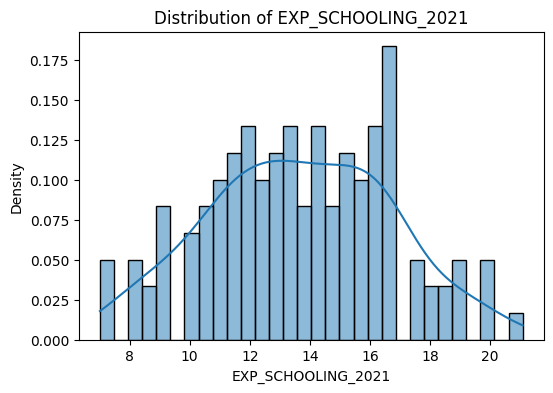

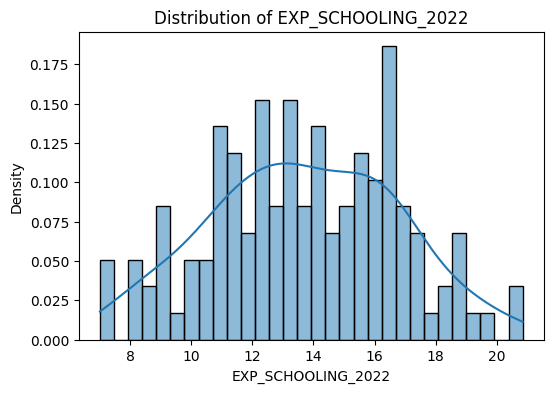

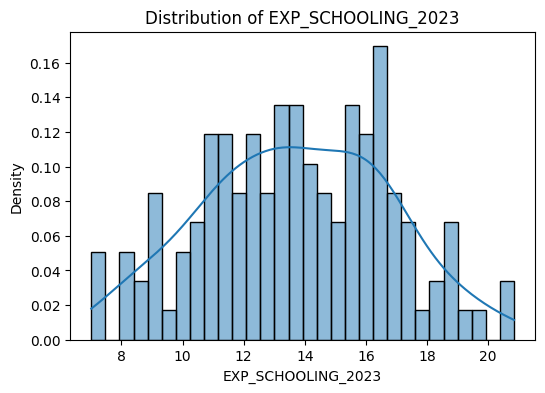

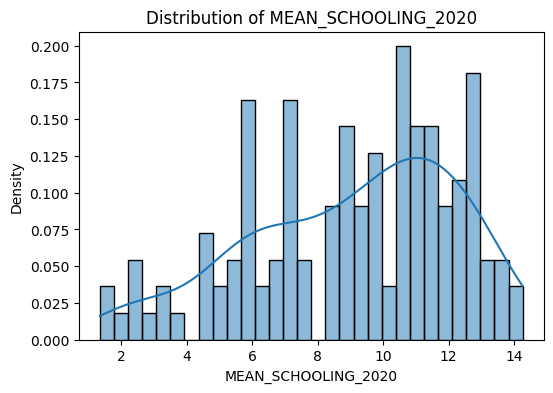

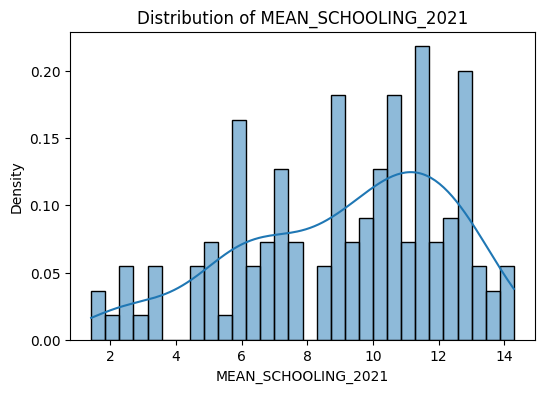

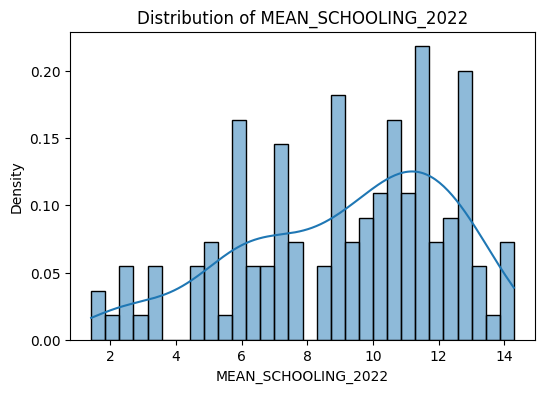

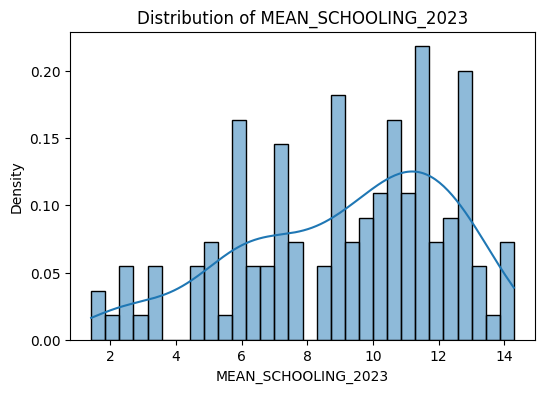

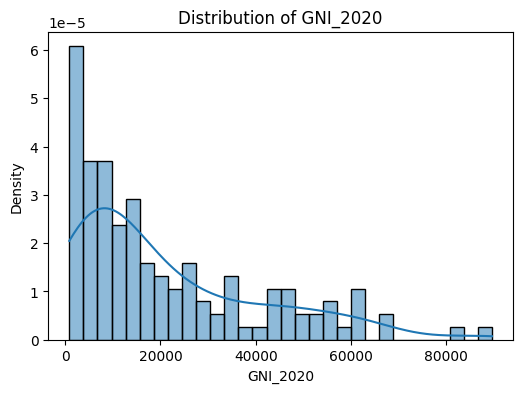

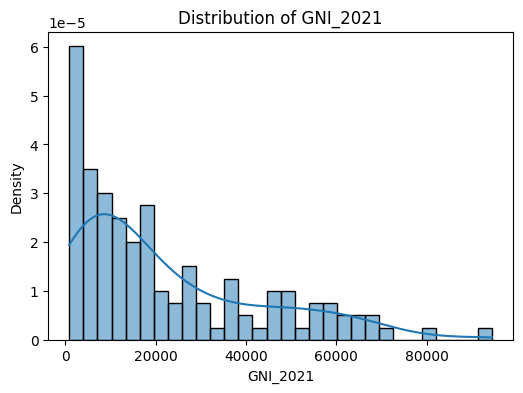

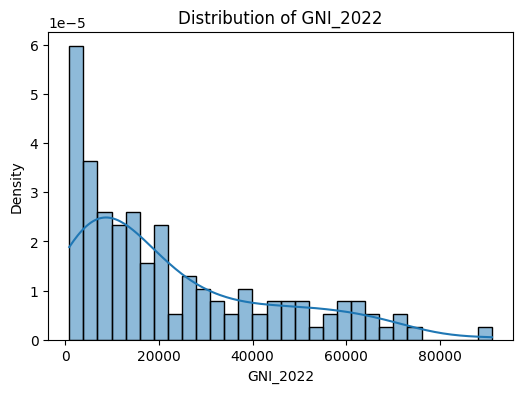

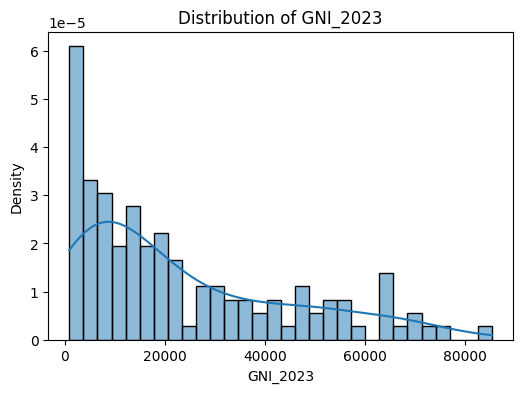

In [4]:
for col in columns:
    plt.figure(figsize=(6, 4))

    sns.histplot(
        df[col],
        bins=30,
        kde=True,
        stat="density"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

    plt.show()


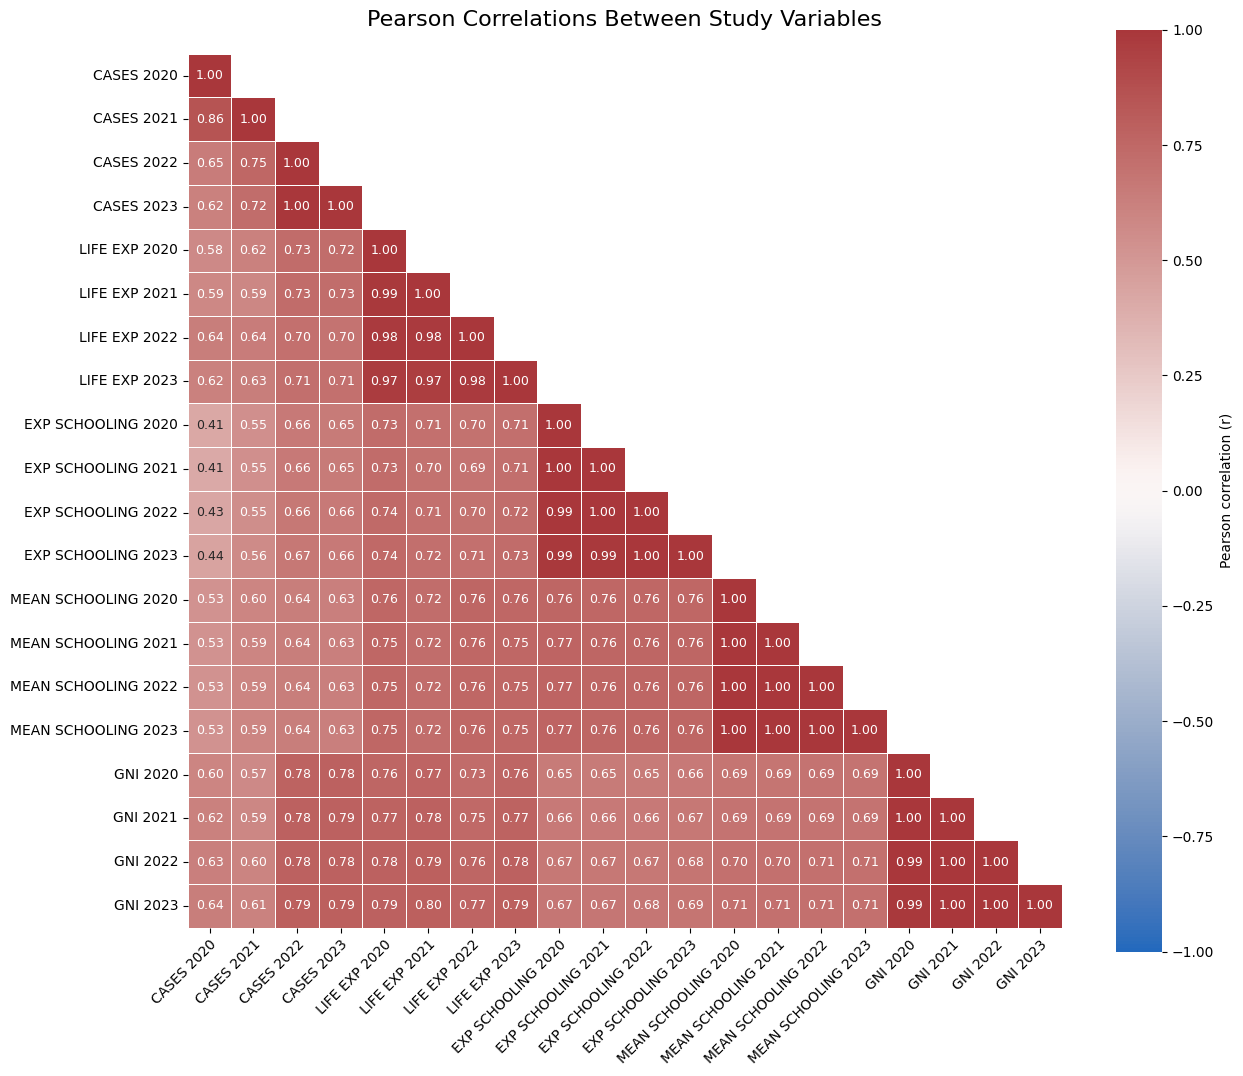

In [5]:
corr = df[columns].corr(method="pearson")

# Show each pair once, with a consistent correlation scale.
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
labels = [col.replace("_", " ") for col in corr.columns]
size = max(9, len(columns) * 0.65)
fig, ax = plt.subplots(figsize=(size, size))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 9},
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"label": "Pearson correlation (r)", "shrink": 0.75},
    ax=ax
)

ax.set_title("Pearson Correlations Between Study Variables", fontsize=16, pad=20)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()


Now that we've recreated the data distribution to align with the paper's original code, we can proceed with recreating the models. 

Although the method is not explicitly stated, the charts imply the original paper scaled all of attributes from 0-1. We will recreate this scaling with sklearn.

In [6]:
scaler = MinMaxScaler()

scaled_values = scaler.fit_transform(
    df[columns]
)

df_scaled = pd.DataFrame(
    scaled_values,
    columns=columns,
    index=df.index
)

print(df_scaled.describe())

       CASES_2020  CASES_2021  CASES_2022  CASES_2023  LIFE_EXP_2020  \
count  128.000000  128.000000  128.000000  128.000000     128.000000   
mean     0.164024    0.232713    0.251096    0.239553       0.623869   
std      0.199229    0.228827    0.275734    0.268287       0.226391   
min      0.000000    0.000000    0.000000    0.000000       0.000000   
25%      0.008029    0.016327    0.022151    0.020664       0.452416   
50%      0.079726    0.187081    0.142403    0.133382       0.635113   
75%      0.294907    0.370381    0.389953    0.374146       0.788465   
max      1.000000    1.000000    1.000000    1.000000       1.000000   

       LIFE_EXP_2021  LIFE_EXP_2022  LIFE_EXP_2023  EXP_SCHOOLING_2020  \
count     128.000000     128.000000     128.000000          128.000000   
mean        0.596148       0.591405       0.602138            0.470179   
std         0.230737       0.214757       0.222961            0.211955   
min         0.000000       0.000000       0.000000     

Next, we will define the feature models to predict the amount of cases in 2021. The first feature model only uses the CASES_2020 column, whereas the second model uses all five columns to predict CASES_2021. Each of these features were put through linear regression, random forest, and AdaBoost models for prediction. We will proceed with recreating all six models.

In [8]:
y = df_scaled["CASES_2021"]

#feature model 1
X1 = df_scaled[["CASES_2020"]
]

#feature model 2
X2 = df_scaled[
    ["CASES_2020",
        "LIFE_EXP_2020",
        "EXP_SCHOOLING_2020",
        "MEAN_SCHOOLING_2020",
        "GNI_2020"
    ]
]

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=1
    ),
    "AdaBoost": AdaBoostRegressor(
        n_estimators=50,
        random_state=0
    )
}

In [9]:
y_22 = df_scaled["CASES_2022"]

#feature model 1
X1_22 = df_scaled[["CASES_2021"]
]

#feature model 2
X2_22 = df_scaled[
    ["CASES_2021",
        "LIFE_EXP_2021",
        "EXP_SCHOOLING_2021",
        "MEAN_SCHOOLING_2021",
        "GNI_2021"
    ]
]

In [10]:
y_23 = df_scaled["CASES_2023"]

#feature model 1
X1_23 = df_scaled[["CASES_2022"]
]

#feature model 2
X2_23 = df_scaled[
    ["CASES_2022",
        "LIFE_EXP_2022",
        "EXP_SCHOOLING_2022",
        "MEAN_SCHOOLING_2022",
        "GNI_2022"
    ]
]

In [11]:
cv = KFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

def evaluate_model(model, X, y, cv):
    scoring = {
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "mse": "neg_mean_squared_error",
        "max_error": make_scorer(
            max_error,
            greater_is_better=False
        )
    }

    cv_results = cross_validate(model, X, y, cv=cv,scoring=scoring)
    r2_scores = cv_results["test_r2"]
    mean_r2 = np.mean(r2_scores)

#error metrics using scikit, * -1

    mae_scores = -cv_results["test_mae"]
    mse_scores = -cv_results["test_mse"]
    max_error_scores = -cv_results["test_max_error"]

    mean_mae = np.mean(mae_scores)
    mean_mse = np.mean(mse_scores)

#rmse averaged across each fold
    rmse_scores = np.sqrt(mse_scores)
    mean_rmse = np.mean(rmse_scores)

    mean_max_error = np.mean(max_error_scores)

    predictions = cross_val_predict(
        model, X, y, cv=cv )


    results = {
        "R2": mean_r2,
        "MAE": mean_mae,
        "MSE": mean_mse,
        "RMSE": mean_rmse,
        "Max Error": mean_max_error
    }

    return results, r2_scores, predictions

In [14]:
#model one
model_data = [("2021",y,X1), ("2022",y_22,X1_22), ("2023",y_23,X1_23)]
results_model1 = {}
fold_scores_model1 = {}
predictions_model1 = {}

for name, model in models.items():
    for year, y_data, X_data in model_data:
        results, fold_scores, predictions = evaluate_model(model, X_data, y_data, cv)

        results_model1[(name, year)] = results
        fold_scores_model1[(name, year)] = fold_scores
        predictions_model1[(name, year)] = predictions


results_df1 = pd.DataFrame(results_model1).T

In [16]:
#model two
model_two_data = [("2021",y,X2), ("2022",y_22,X2_22), ("2023",y_23,X2_23)]


results_model2 = {}
fold_scores_model2 = {}
predictions_model2 = {}

for name, model in models.items():
    for year, y_data, X_data in model_two_data:
        results, fold_scores, predictions = evaluate_model(model, X_data, y_data, cv)
        results_model2[(name, year)] = results
        fold_scores_model2[(name, year)] = fold_scores
        predictions_model2[(name, year)] = predictions


results_df2 = pd.DataFrame(results_model2).T

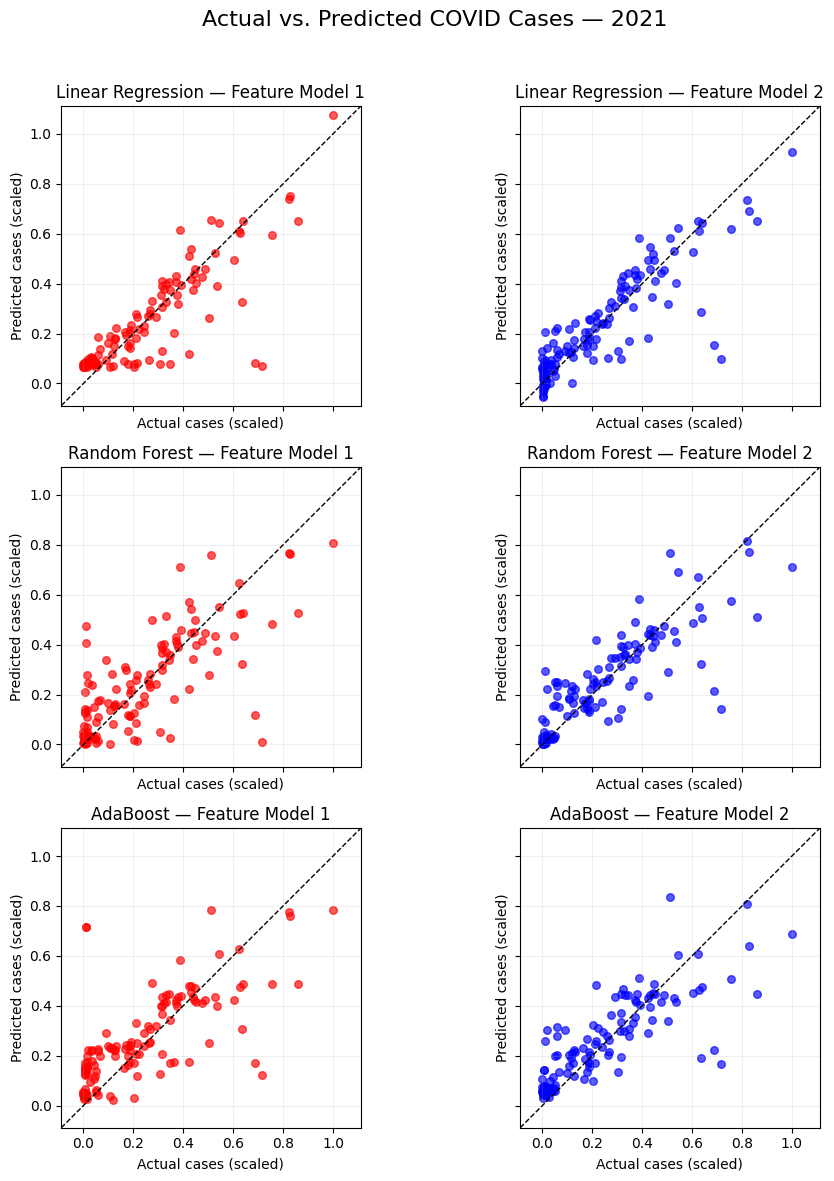

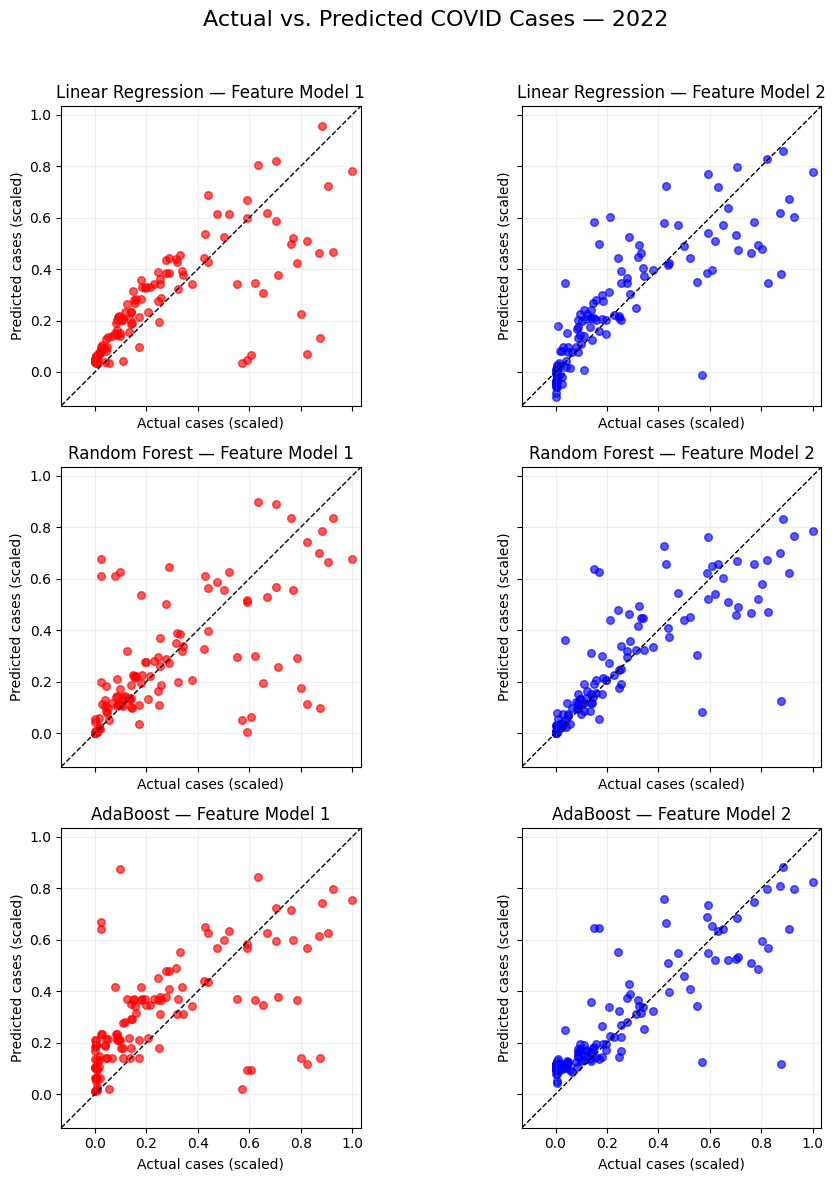

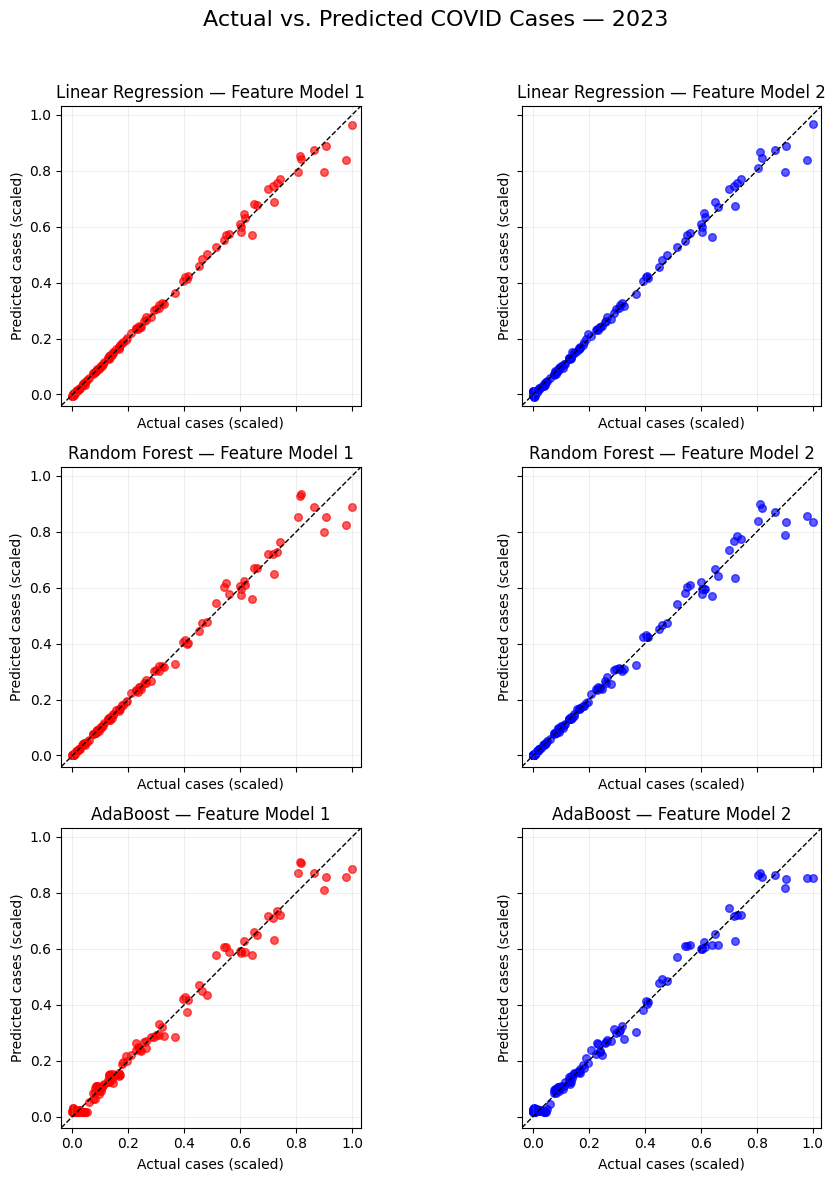

In [21]:
# One figure per target year: algorithms in rows, feature models in columns.
prediction_sets = [
    ("Feature Model 1", predictions_model1, "red"),
    ("Feature Model 2", predictions_model2, "blue")
]

for year, actual, _ in model_data:
    fig, axes = plt.subplots(
        len(models), 2,
        figsize=(10, 4 * len(models)),
        sharex=True, sharey=True, squeeze=False
    )

    # Include predictions outside 0–1 so no points are clipped.
    all_values = np.concatenate(
        [np.asarray(actual)] +
        [np.asarray(predictions[(name, year)])
         for _, predictions, _ in prediction_sets
         for name in models]
    )
    lower = min(0, np.nanmin(all_values))
    upper = max(1, np.nanmax(all_values))
    padding = 0.03 * (upper - lower)
    limits = (lower - padding, upper + padding)

    for row, name in enumerate(models):
        for col, (feature_name, predictions, color) in enumerate(prediction_sets):
            ax = axes[row, col]
            ax.scatter(
                actual,
                predictions[(name, year)],
                color=color,
                alpha=0.65,
                s=30
            )
            ax.plot(limits, limits, linestyle="--", color="black", linewidth=1)
            ax.set_title(f"{name} — {feature_name}")
            ax.set_xlabel("Actual cases (scaled)")
            ax.set_ylabel("Predicted cases (scaled)")
            ax.set_xlim(limits)
            ax.set_ylim(limits)
            ax.set_aspect("equal", adjustable="box")
            ax.grid(alpha=0.2)

    fig.suptitle(f"Actual vs. Predicted COVID Cases — {year}", fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
